# CV5570 - Computer Vision for Construction Engineering Asssignment 3
## Visual SLAM

### Importing the necessary packages

In [1]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt
from tqdm import tqdm
import pandas as pd

try:
    import gtsam
    GTSAM_AVAILABLE = True
except ImportError:
    GTSAM_AVAILABLE = False

print("Core packages imported")
print("GTSAM available:", GTSAM_AVAILABLE)

Core packages imported
GTSAM available: False


### Path Configuration

In [2]:
BASE_DIR = os.getcwd()

SEQ_DIR = os.path.join(BASE_DIR, "data", "sequences", "05")

LEFT_DIR = os.path.join(SEQ_DIR, "image_0")
RIGHT_DIR = os.path.join(SEQ_DIR, "image_1")

CALIB_FILE = os.path.join(SEQ_DIR, "calib.txt")
TIMES_FILE = os.path.join(SEQ_DIR, "times.txt")

POSE_FILE = os.path.join(BASE_DIR, "data", "poses", "05.txt")

OUTPUT_DIR = os.path.join(BASE_DIR, "output")

os.makedirs(OUTPUT_DIR, exist_ok=True)

print("Base directory:", BASE_DIR)
print("Sequence directory:", SEQ_DIR)
print("Output directory:", OUTPUT_DIR)

Base directory: d:\CV5570\CV5570_Assignment_3
Sequence directory: d:\CV5570\CV5570_Assignment_3\data\sequences\05
Output directory: d:\CV5570\CV5570_Assignment_3\output


### Verifying the Dataset files

In [3]:
required_paths = {
    "Left images": LEFT_DIR,
    "Right images": RIGHT_DIR,
    "Calibration": CALIB_FILE,
    "Timestamps": TIMES_FILE,
    "Ground truth poses": POSE_FILE
}

for name, path in required_paths.items():
    exists = os.path.exists(path)
    print(f"{name}: {'FOUND' if exists else 'NOT FOUND'}")

Left images: FOUND
Right images: FOUND
Calibration: FOUND
Timestamps: FOUND
Ground truth poses: FOUND


### Loading image lists

In [4]:
left_images = sorted([
    f for f in os.listdir(LEFT_DIR)
    if f.endswith(".png")
])

right_images = sorted([
    f for f in os.listdir(RIGHT_DIR)
    if f.endswith(".png")
])

print("Number of LEFT images :", len(left_images))
print("Number of RIGHT images:", len(right_images))

print("\nFirst 5 left images:")
print(left_images[:5])

print("\nFirst 5 right images:")
print(right_images[:5])

Number of LEFT images : 2761
Number of RIGHT images: 2761

First 5 left images:
['000000.png', '000001.png', '000002.png', '000003.png', '000004.png']

First 5 right images:
['000000.png', '000001.png', '000002.png', '000003.png', '000004.png']


### Loading Timestamps

In [5]:
timestamps = np.loadtxt(TIMES_FILE)

print("Number of timestamps:", len(timestamps))

print("\nFirst 5 timestamps:")
print(timestamps[:5])

print("\nLast 5 timestamps:")
print(timestamps[-5:])

Number of timestamps: 2761

First 5 timestamps:
[0.        0.1042283 0.2084765 0.3127291 0.4169786]

Last 5 timestamps:
[287.1205 287.2246 287.3287 287.4329 287.537 ]


In [6]:
print("\nDATASET CONSISTENCY CHECK")

print("Left images :", len(left_images))
print("Right images:", len(right_images))
print("Timestamps  :", len(timestamps))

if len(left_images) == len(right_images) == len(timestamps):
    print("\nDataset is consistent")
else:
    print("\n⚠ WARNING: Number of files does not match")


DATASET CONSISTENCY CHECK
Left images : 2761
Right images: 2761
Timestamps  : 2761

Dataset is consistent


### Loading Ground Truth Poses

In [7]:
gt_poses = np.loadtxt(POSE_FILE)

print("Ground truth pose array shape:", gt_poses.shape)

print("\nFirst pose (12 values):")
print(gt_poses[0])

Ground truth pose array shape: (2761, 12)

First pose (12 values):
[1.000000e+00 1.197625e-11 1.704638e-10 1.110223e-16 1.197625e-11
 1.000000e+00 3.562503e-10 0.000000e+00 1.704638e-10 3.562503e-10
 1.000000e+00 2.220446e-16]


In [8]:
first_pose = gt_poses[0].reshape(3, 4)

print("First ground truth pose (3x4):")
print(first_pose)

First ground truth pose (3x4):
[[1.000000e+00 1.197625e-11 1.704638e-10 1.110223e-16]
 [1.197625e-11 1.000000e+00 3.562503e-10 0.000000e+00]
 [1.704638e-10 3.562503e-10 1.000000e+00 2.220446e-16]]


### Reading Calibration File

In [9]:
with open(CALIB_FILE, "r") as f:
    calib_lines = f.readlines()

for line in calib_lines:
    print(line.strip())

P0: 7.070912000000e+02 0.000000000000e+00 6.018873000000e+02 0.000000000000e+00 0.000000000000e+00 7.070912000000e+02 1.831104000000e+02 0.000000000000e+00 0.000000000000e+00 0.000000000000e+00 1.000000000000e+00 0.000000000000e+00
P1: 7.070912000000e+02 0.000000000000e+00 6.018873000000e+02 -3.798145000000e+02 0.000000000000e+00 7.070912000000e+02 1.831104000000e+02 0.000000000000e+00 0.000000000000e+00 0.000000000000e+00 1.000000000000e+00 0.000000000000e+00
P2: 7.070912000000e+02 0.000000000000e+00 6.018873000000e+02 4.688783000000e+01 0.000000000000e+00 7.070912000000e+02 1.831104000000e+02 1.178601000000e-01 0.000000000000e+00 0.000000000000e+00 1.000000000000e+00 6.203223000000e-03
P3: 7.070912000000e+02 0.000000000000e+00 6.018873000000e+02 -3.334597000000e+02 0.000000000000e+00 7.070912000000e+02 1.831104000000e+02 1.930130000000e+00 0.000000000000e+00 0.000000000000e+00 1.000000000000e+00 3.318498000000e-03


### Parse Kitti calibration matrices

In [10]:
calib = {}

with open(CALIB_FILE, "r") as f:
    for line in f:
        parts = line.strip().split()
        
        if len(parts) > 1:
            key = parts[0].replace(":", "")
            values = np.array(
                [float(x) for x in parts[1:]],
                dtype=np.float64
            )
            
            calib[key] = values.reshape(3, 4)

P0 = calib["P0"]
P1 = calib["P1"]

print("P0:")
print(P0)

print("\nP1:")
print(P1)

P0:
[[707.0912   0.     601.8873   0.    ]
 [  0.     707.0912 183.1104   0.    ]
 [  0.       0.       1.       0.    ]]

P1:
[[ 707.0912    0.      601.8873 -379.8145]
 [   0.      707.0912  183.1104    0.    ]
 [   0.        0.        1.        0.    ]]


### Camera Intrinsics and Stereo Baseline

In [11]:
# Camera intrinsic parameters
fx = P0[0, 0]
fy = P0[1, 1]

cx = P0[0, 2]
cy = P0[1, 2]

K = np.array([
    [fx, 0,  cx],
    [0,  fy, cy],
    [0,  0,  1]
])

# Camera translation terms
tx_left = P0[0, 3] / P0[0, 0]
tx_right = P1[0, 3] / P1[0, 0]

# Stereo baseline in metres
baseline = abs(tx_right - tx_left)

print("Camera matrix K:")
print(K)

print("\nfx =", fx)
print("fy =", fy)
print("cx =", cx)
print("cy =", cy)

print("\nStereo baseline =", baseline, "metres")

Camera matrix K:
[[707.0912   0.     601.8873]
 [  0.     707.0912 183.1104]
 [  0.       0.       1.    ]]

fx = 707.0912
fy = 707.0912
cx = 601.8873
cy = 183.1104

Stereo baseline = 0.5371506532679237 metres


### Loading one stereo image pair

In [12]:
frame_id = 0

left_path = os.path.join(LEFT_DIR, left_images[frame_id])
right_path = os.path.join(RIGHT_DIR, right_images[frame_id])

left_img = cv2.imread(left_path, cv2.IMREAD_GRAYSCALE)
right_img = cv2.imread(right_path, cv2.IMREAD_GRAYSCALE)

print("Left image shape :", left_img.shape)
print("Right image shape:", right_img.shape)

Left image shape : (370, 1226)
Right image shape: (370, 1226)


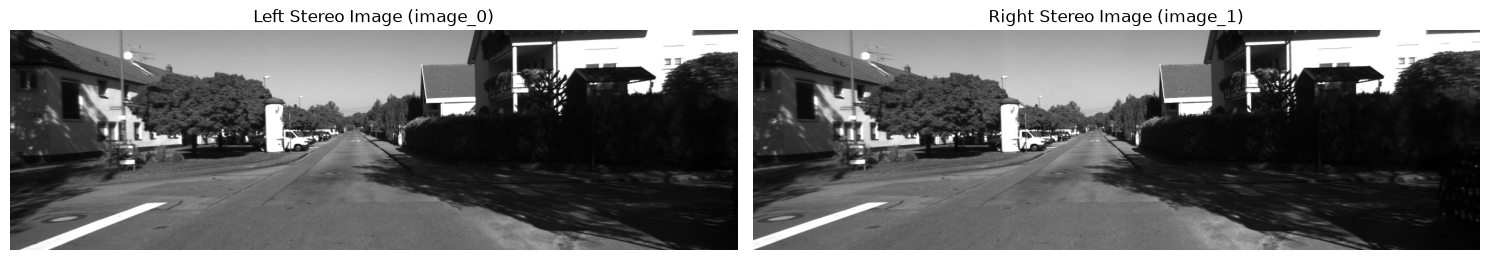

In [13]:
plt.figure(figsize=(15, 6))

plt.subplot(1, 2, 1)
plt.imshow(left_img, cmap="gray")
plt.title("Left Stereo Image (image_0)")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(right_img, cmap="gray")
plt.title("Right Stereo Image (image_1)")
plt.axis("off")

plt.tight_layout()
plt.show()

### Task 2. Visual Odometry and Trajectory Drift

In [14]:
DISPARITY_DIR = os.path.join(OUTPUT_DIR, "disparity")
DEPTH_DIR = os.path.join(OUTPUT_DIR, "depth")
PLOT_DIR = os.path.join(OUTPUT_DIR, "plots")

os.makedirs(DISPARITY_DIR, exist_ok=True)
os.makedirs(DEPTH_DIR, exist_ok=True)
os.makedirs(PLOT_DIR, exist_ok=True)

print("Output directories created successfully")

Output directories created successfully


In [15]:
frame_id = 0

left_path = os.path.join(LEFT_DIR, left_images[frame_id])
right_path = os.path.join(RIGHT_DIR, right_images[frame_id])

left_img = cv2.imread(left_path, cv2.IMREAD_GRAYSCALE)
right_img = cv2.imread(right_path, cv2.IMREAD_GRAYSCALE)

print("Left image shape :", left_img.shape)
print("Right image shape:", right_img.shape)

print("Frame:", left_images[frame_id])

Left image shape : (370, 1226)
Right image shape: (370, 1226)
Frame: 000000.png


#### Creating Stereo SGBM Matcher

In [16]:
min_disp = 0
num_disp = 128
block_size = 5

stereo = cv2.StereoSGBM_create(
    minDisparity=min_disp,
    numDisparities=num_disp,
    blockSize=block_size,
    
    P1=8 * block_size * block_size,
    P2=32 * block_size * block_size,
    
    disp12MaxDiff=1,
    uniquenessRatio=10,
    speckleWindowSize=100,
    speckleRange=32,
    
    preFilterCap=63,
    mode=cv2.STEREO_SGBM_MODE_SGBM_3WAY
)

print("StereoSGBM matcher created successfully")

StereoSGBM matcher created successfully


In [17]:
# Computing disparity map
disparity = stereo.compute(left_img, right_img).astype(np.float32) / 16.0

print("Disparity shape:", disparity.shape)
print("Minimum disparity:", np.min(disparity))
print("Maximum disparity:", np.max(disparity))

Disparity shape: (370, 1226)
Minimum disparity: -1.0
Maximum disparity: 78.25


**Why `/16.0`?**
OpenCV stores the disparity using fixed-point precision.

So we divide by:
``` 16 ```
to get the actual disparity values in pixels.

In [18]:
# Cleaning invalid disparity values
valid_disparity = disparity > 0

disparity_clean = disparity.copy()

disparity_clean[~valid_disparity] = np.nan

print("Valid disparity pixels:",
      np.sum(valid_disparity))

print("Invalid disparity pixels:",
      np.sum(~valid_disparity))

Valid disparity pixels: 370491
Invalid disparity pixels: 83129


In [19]:
# Converting disparity to depth

depth = np.full(disparity.shape, np.nan, dtype=np.float32)

valid = disparity > 0

depth[valid] = (fx * baseline) / disparity[valid]

print("Depth map created successfully")

print("Minimum valid depth:",
      np.nanmin(depth), "metres")

print("Maximum valid depth:",
      np.nanmax(depth), "metres")

Depth map created successfully
Minimum valid depth: 4.8538594 metres
Maximum valid depth: 675.22577 metres


In [20]:
# Clip depth for visualization

MAX_DEPTH = 80  # in mtrs

depth_visual = depth.copy()

depth_visual[depth_visual > MAX_DEPTH] = MAX_DEPTH

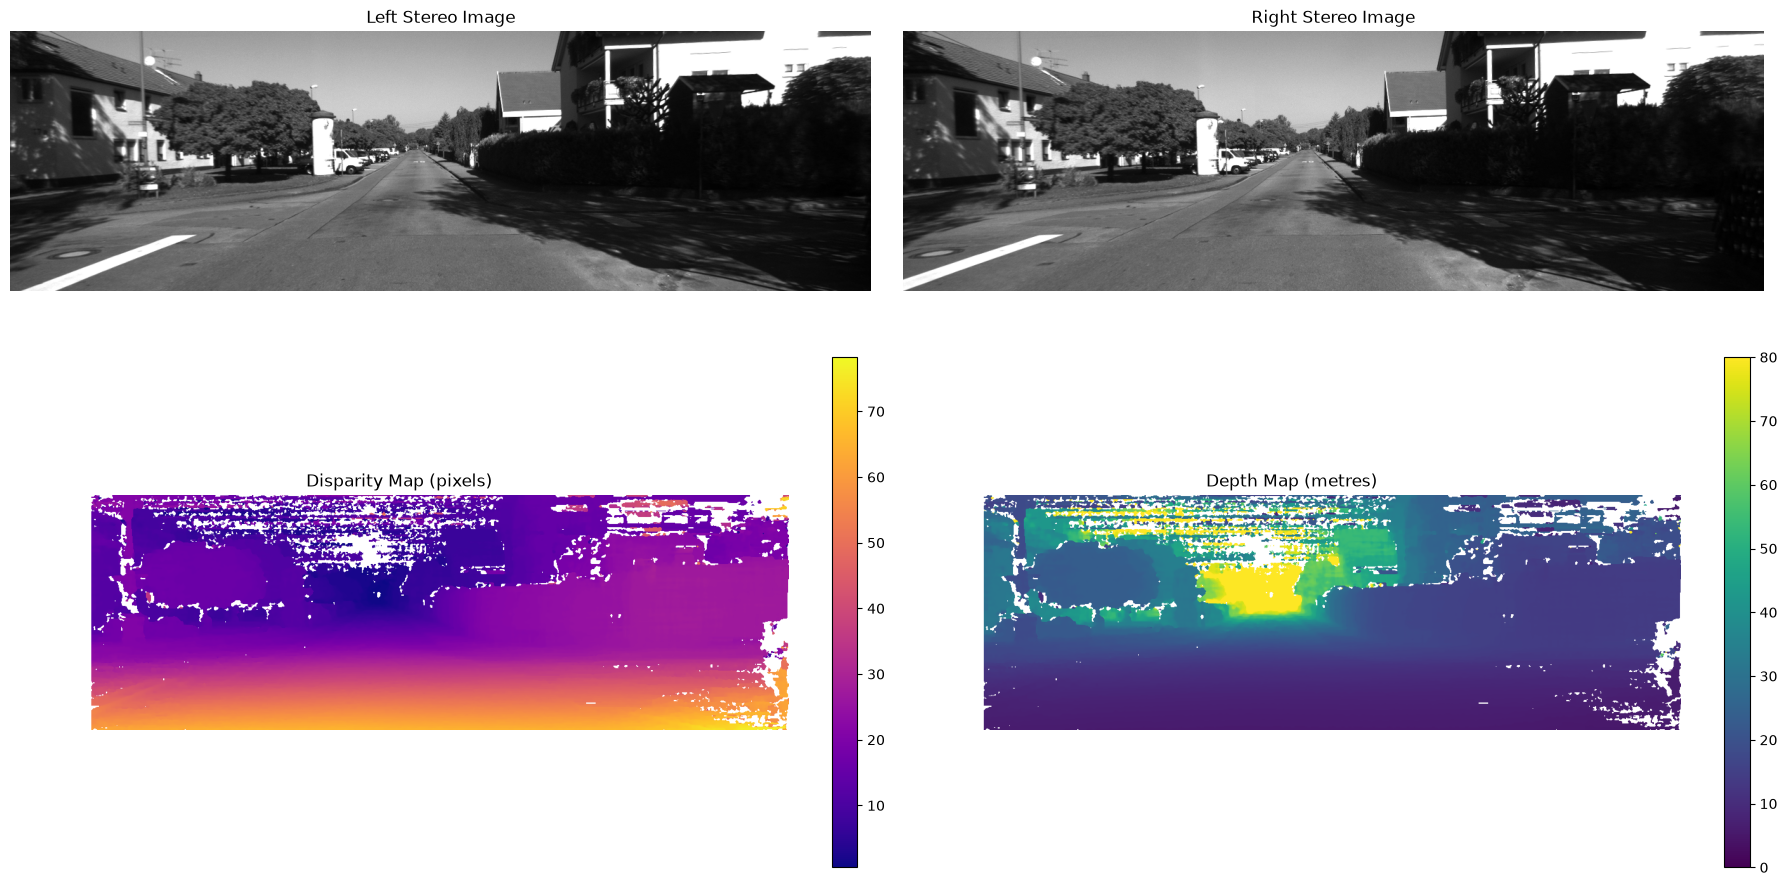

In [21]:
# Visualizing Stereo, Disparity and depth

plt.figure(figsize=(18, 10))

# Left image
plt.subplot(2, 2, 1)
plt.imshow(left_img, cmap="gray")
plt.title("Left Stereo Image")
plt.axis("off")


# Right image
plt.subplot(2, 2, 2)
plt.imshow(right_img, cmap="gray")
plt.title("Right Stereo Image")
plt.axis("off")


# Disparity map
plt.subplot(2, 2, 3)

disp_plot = plt.imshow(
    disparity_clean,
    cmap="plasma"
)

plt.title("Disparity Map (pixels)")
plt.axis("off")
plt.colorbar(disp_plot, fraction=0.046)


# Depth map
plt.subplot(2, 2, 4)

depth_plot = plt.imshow(
    depth_visual,
    cmap="viridis",
    vmin=0,
    vmax=MAX_DEPTH
)

plt.title("Depth Map (metres)")
plt.axis("off")
plt.colorbar(depth_plot, fraction=0.046)

plt.tight_layout()
plt.show()

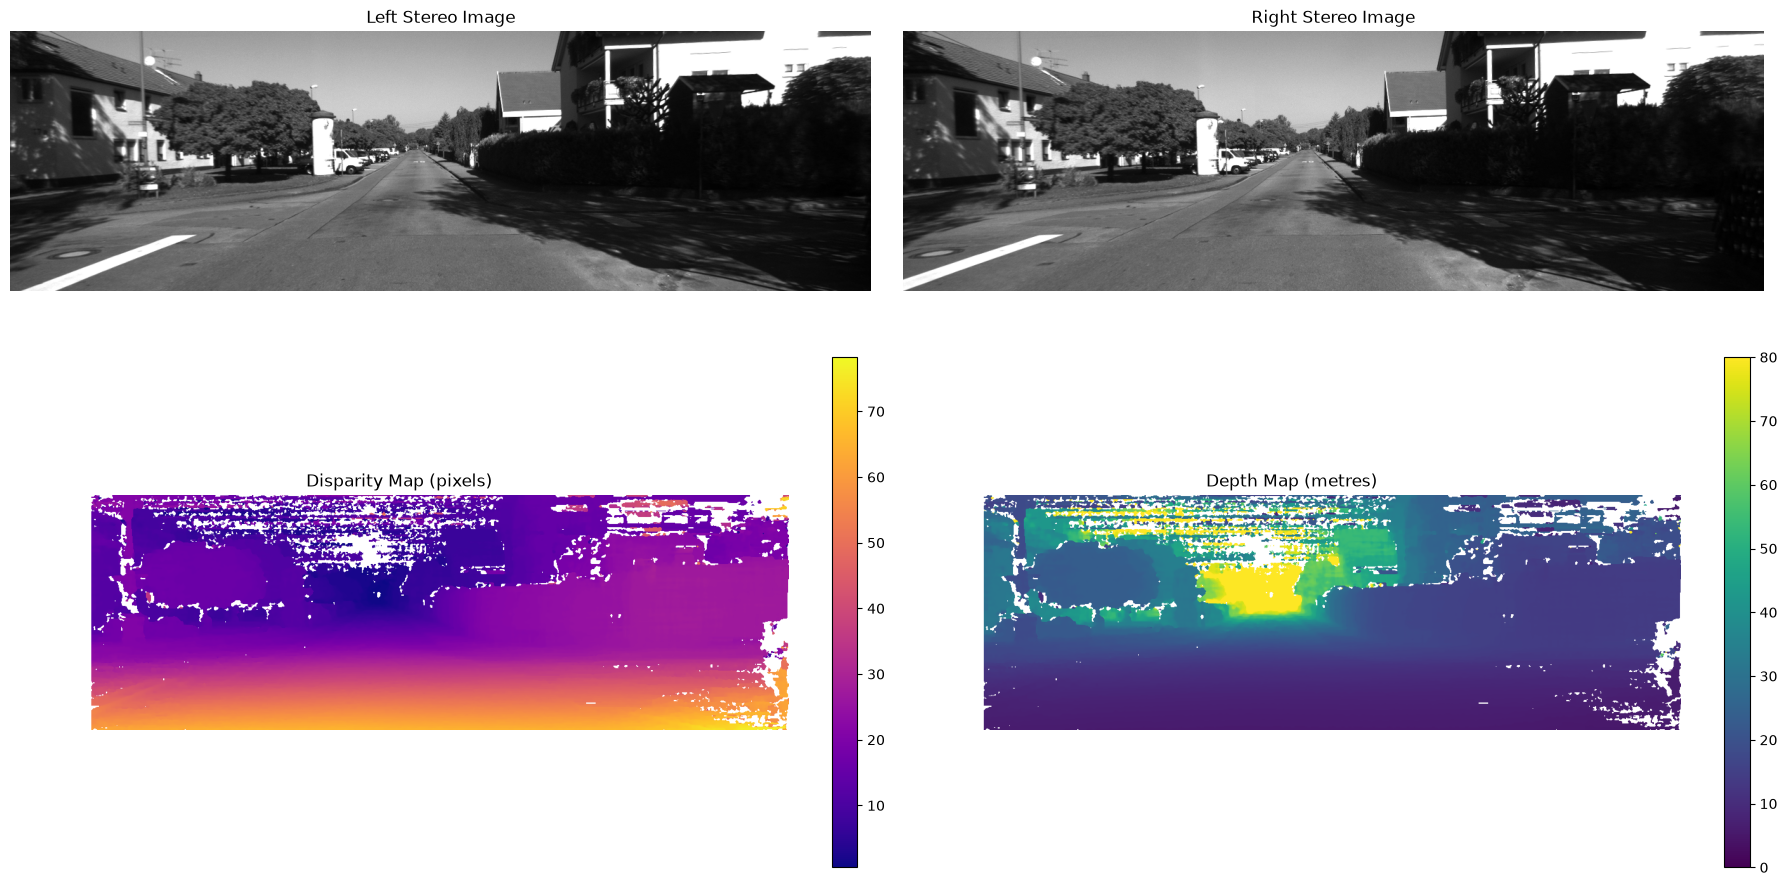

Figure saved to:
d:\CV5570\CV5570_Assignment_3\output\plots\stereo_disparity_depth_000000.png


In [22]:
figure_path = os.path.join(
    PLOT_DIR,
    f"stereo_disparity_depth_{frame_id:06d}.png"
)

plt.figure(figsize=(18, 10))

plt.subplot(2, 2, 1)
plt.imshow(left_img, cmap="gray")
plt.title("Left Stereo Image")
plt.axis("off")

plt.subplot(2, 2, 2)
plt.imshow(right_img, cmap="gray")
plt.title("Right Stereo Image")
plt.axis("off")

plt.subplot(2, 2, 3)
disp_plot = plt.imshow(disparity_clean, cmap="plasma")
plt.title("Disparity Map (pixels)")
plt.axis("off")
plt.colorbar(disp_plot, fraction=0.046)

plt.subplot(2, 2, 4)
depth_plot = plt.imshow(
    depth_visual,
    cmap="viridis",
    vmin=0,
    vmax=MAX_DEPTH
)
plt.title("Depth Map (metres)")
plt.axis("off")
plt.colorbar(depth_plot, fraction=0.046)

plt.tight_layout()

plt.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Figure saved to:")
print(figure_path)

In [23]:
disparity_path = os.path.join(
    DISPARITY_DIR,
    f"disparity_{frame_id:06d}.npy"
)

depth_path = os.path.join(
    DEPTH_DIR,
    f"depth_{frame_id:06d}.npy"
)

np.save(disparity_path, disparity)
np.save(depth_path, depth)

print("Disparity saved:", disparity_path)
print("Depth saved:", depth_path)

Disparity saved: d:\CV5570\CV5570_Assignment_3\output\disparity\disparity_000000.npy
Depth saved: d:\CV5570\CV5570_Assignment_3\output\depth\depth_000000.npy


In [24]:
# ORB Feature Detection

orb = cv2.ORB_create(
    nfeatures=2000,
    scaleFactor=1.2,
    nlevels=8
)

print("ORB detector created successfully")

ORB detector created successfully


In [25]:
# Detecting ORB Features in left image
keypoints_left, descriptors_left = orb.detectAndCompute(
    left_img,
    None
)

print("Number of ORB keypoints:", len(keypoints_left))
print("Descriptor shape:", descriptors_left.shape)

Number of ORB keypoints: 2000
Descriptor shape: (2000, 32)


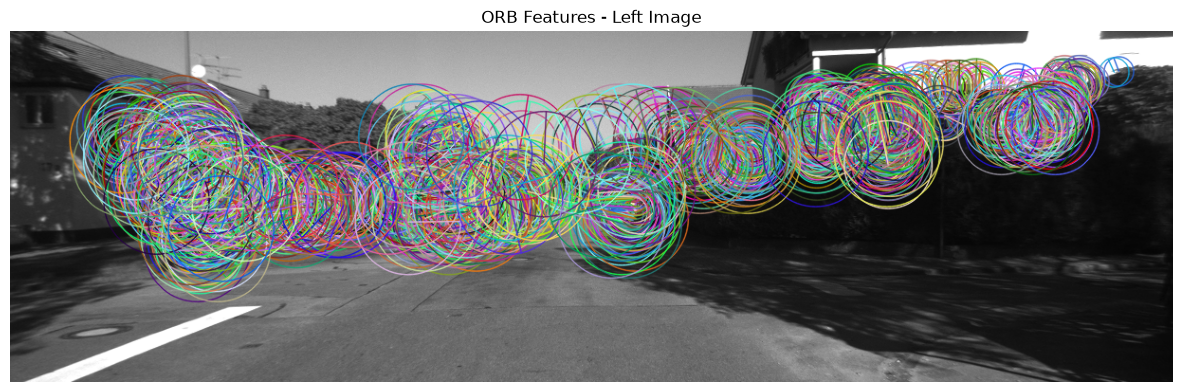

In [26]:
# Visualize ORB Keypoints

keypoint_image = cv2.drawKeypoints(
    left_img,
    keypoints_left,
    None,
    flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS
)

plt.figure(figsize=(15, 6))

plt.imshow(keypoint_image)
plt.title("ORB Features - Left Image")
plt.axis("off")

plt.show()

In [27]:
# Detecting ORB Features in right image

keypoints_right, descriptors_right = orb.detectAndCompute(
    right_img,
    None
)

print("Number of ORB keypoints in right image:",
      len(keypoints_right))

print("Descriptor shape:",
      descriptors_right.shape)

Number of ORB keypoints in right image: 2000
Descriptor shape: (2000, 32)


In [28]:
# Match left and right ORB Features

bf = cv2.BFMatcher(
    cv2.NORM_HAMMING,
    crossCheck=True
)

matches_stereo = bf.match(
    descriptors_left,
    descriptors_right
)

matches_stereo = sorted(
    matches_stereo,
    key=lambda x: x.distance
)

print("Total stereo matches:", len(matches_stereo))

Total stereo matches: 1064


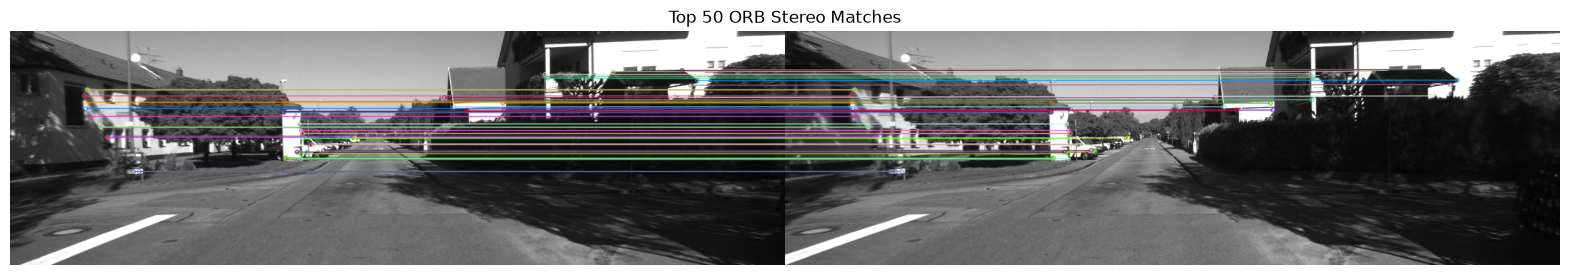

In [29]:
# Visualizing Best Stereo Matches

match_image = cv2.drawMatches(
    left_img,
    keypoints_left,
    right_img,
    keypoints_right,
    matches_stereo[:50],
    None,
    flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS
)

plt.figure(figsize=(20, 8))

plt.imshow(match_image)

plt.title("Top 50 ORB Stereo Matches")
plt.axis("off")

plt.show()

In [30]:
# Filter Reliable Stereo Matches
good_stereo_matches = []

MAX_VERTICAL_DIFF = 2.0   # pixels
MIN_DISPARITY = 1.0       # pixels
MAX_DISPARITY = 128.0     # pixels

for match in matches_stereo:

    # Coordinates in left image
    u_left, v_left = keypoints_left[match.queryIdx].pt

    # Coordinates in right image
    u_right, v_right = keypoints_right[match.trainIdx].pt

    # Stereo disparity
    disparity_value = u_left - u_right

    # Vertical difference
    vertical_diff = abs(v_left - v_right)

    # Keep only geometrically reasonable stereo matches
    if (
        disparity_value > MIN_DISPARITY
        and disparity_value < MAX_DISPARITY
        and vertical_diff < MAX_VERTICAL_DIFF
    ):
        good_stereo_matches.append(match)

print("Original stereo matches:", len(matches_stereo))
print("Reliable stereo matches:", len(good_stereo_matches))

Original stereo matches: 1064
Reliable stereo matches: 888


In [31]:
# Triangulate Stereo Features into 3D Points
points_3d = []
points_2d_left = []

for match in good_stereo_matches:

    # Left image coordinates
    u_left, v_left = keypoints_left[match.queryIdx].pt

    # Right image coordinates
    u_right, v_right = keypoints_right[match.trainIdx].pt

    # Compute disparity
    d = u_left - u_right

    # Compute depth
    Z = (fx * baseline) / d

    # Convert pixel coordinates to 3D camera coordinates
    X = (u_left - cx) * Z / fx
    Y = (v_left - cy) * Z / fy

    points_3d.append([X, Y, Z])
    points_2d_left.append([u_left, v_left])

points_3d = np.array(points_3d, dtype=np.float32)
points_2d_left = np.array(points_2d_left, dtype=np.float32)

print("3D points shape:", points_3d.shape)
print("2D points shape:", points_2d_left.shape)

print("\nFirst 5 3D points:")
print(points_3d[:5])

3D points shape: (888, 3)
2D points shape: (888, 2)

First 5 3D points:
[[-21.562675   -4.0720434  31.799768 ]
 [-19.898712   -0.6880642  31.400026 ]
 [-21.428389   -2.1920156  31.799768 ]
 [  8.741687   -4.1221085  25.320967 ]
 [-20.721653   -3.9306471  30.527775 ]]


In [32]:
# Filter 3D Points by Depth
MIN_DEPTH = 1.0
MAX_DEPTH_VO = 80.0

depth_mask = (
    points_3d[:, 2] > MIN_DEPTH
) & (
    points_3d[:, 2] < MAX_DEPTH_VO
)

points_3d_filtered = points_3d[depth_mask]
points_2d_filtered = points_2d_left[depth_mask]

print("3D points before depth filtering:", len(points_3d))
print("3D points after depth filtering :", len(points_3d_filtered))

3D points before depth filtering: 888
3D points after depth filtering : 827


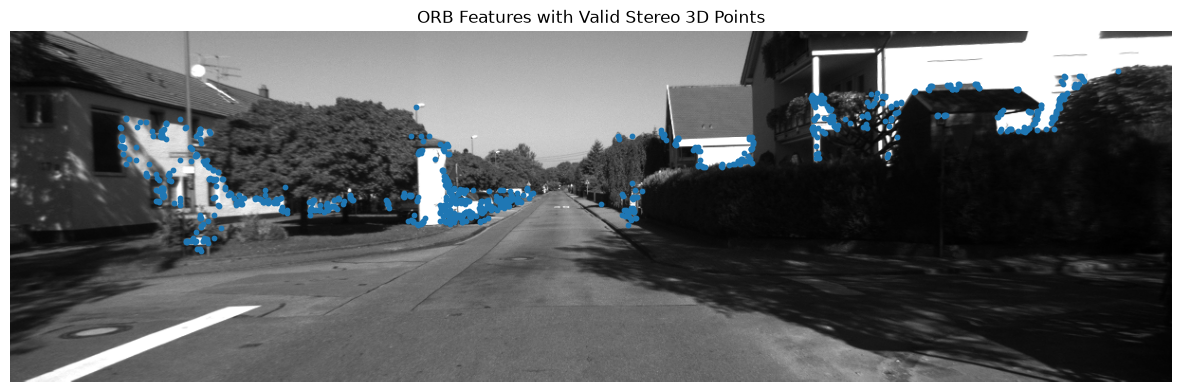

In [33]:
# Visualize Features with valid 3D depth

plt.figure(figsize=(15, 6))

plt.imshow(left_img, cmap="gray")

plt.scatter(
    points_2d_filtered[:, 0],
    points_2d_filtered[:, 1],
    s=10
)

plt.title("ORB Features with Valid Stereo 3D Points")

plt.xlim(0, left_img.shape[1])
plt.ylim(left_img.shape[0], 0)

plt.axis("off")

plt.show()

### Task 2(c) Stereo Visual Odometry

Stereo visual odometry estimates the motion of the camera between consecutive
stereo frames. ORB features are detected in the left image and their depth is
obtained from the corresponding stereo disparity. These 3D points are matched
with 2D features in the next frame. `cv2.solvePnPRansac` estimates the relative
camera motion robustly, and the relative transformations are accumulated to
obtain the complete camera trajectory.

In [34]:
# Stereo Visual Odometry - Helper Functions

# ORB detector
orb = cv2.ORB_create(
    nfeatures=2000,
    scaleFactor=1.2,
    nlevels=8
)

# BFMatcher for ORB binary descriptors
bf = cv2.BFMatcher(cv2.NORM_HAMMING)


def create_stereo_matcher():
    """
    Create StereoSGBM matcher.
    """

    block_size = 5

    stereo = cv2.StereoSGBM_create(
        minDisparity=0,
        numDisparities=128,
        blockSize=block_size,

        P1=8 * block_size * block_size,
        P2=32 * block_size * block_size,

        disp12MaxDiff=1,
        uniquenessRatio=10,

        speckleWindowSize=100,
        speckleRange=32,

        mode=cv2.STEREO_SGBM_MODE_SGBM_3WAY
    )

    return stereo


stereo_matcher = create_stereo_matcher()


def compute_disparity(left_img, right_img):
    """
    Compute stereo disparity map.
    """

    disparity = stereo_matcher.compute(
        left_img,
        right_img
    ).astype(np.float32) / 16.0

    return disparity


def get_stereo_3d_points(left_img, right_img):
    """
    Detect ORB features in the left image and assign 3D coordinates
    using stereo disparity.
    """

    # Detect ORB features
    keypoints, descriptors = orb.detectAndCompute(
        left_img,
        None
    )

    if descriptors is None or len(keypoints) == 0:
        return [], None, np.empty((0, 3), dtype=np.float32)

    # Compute disparity
    disparity = compute_disparity(left_img, right_img)

    points_3d = []
    valid_keypoints = []
    valid_descriptors = []

    height, width = disparity.shape

    for i, kp in enumerate(keypoints):

        u, v = kp.pt

        x = int(round(u))
        y = int(round(v))

        # Check image boundaries
        if x < 0 or x >= width or y < 0 or y >= height:
            continue

        d = disparity[y, x]

        # Valid disparity
        if d <= 1.0:
            continue

        # Depth
        Z = (fx * baseline) / d

        # Keep reliable depth points
        if Z < 1.0 or Z > 80.0:
            continue

        # Back-project pixel into 3D
        X = (u - cx) * Z / fx
        Y = (v - cy) * Z / fy

        points_3d.append([X, Y, Z])
        valid_keypoints.append(kp)
        valid_descriptors.append(descriptors[i])

    if len(points_3d) == 0:

        return (
            [],
            None,
            np.empty((0, 3), dtype=np.float32)
        )

    points_3d = np.array(
        points_3d,
        dtype=np.float32
    )

    valid_descriptors = np.array(
        valid_descriptors,
        dtype=np.uint8
    )

    return (
        valid_keypoints,
        valid_descriptors,
        points_3d
    )


print("Stereo VO helper functions created successfully")

Stereo VO helper functions created successfully


#### Testing Relative Motion Estimation

Before processing the entire sequence, the visual odometry pipeline is tested
using two consecutive frames. The 3D points obtained from Frame k are matched
with the corresponding 2D observations in Frame k+1 and the relative motion is
estimated using `solvePnPRansac`.

In [35]:
# Test VO between frame 0 and frame 1

# Load frame 0 stereo pair
left_0 = cv2.imread(
    os.path.join(LEFT_DIR, left_images[0]),
    cv2.IMREAD_GRAYSCALE
)

right_0 = cv2.imread(
    os.path.join(RIGHT_DIR, right_images[0]),
    cv2.IMREAD_GRAYSCALE
)

# Load frame 1 left image
left_1 = cv2.imread(
    os.path.join(LEFT_DIR, left_images[1]),
    cv2.IMREAD_GRAYSCALE
)

# Get 3D features from Frame 0
kp0, desc0, points3d_0 = get_stereo_3d_points(
    left_0,
    right_0
)

# Detect ORB features in Frame 1
kp1, desc1 = orb.detectAndCompute(
    left_1,
    None
)

print("Frame 0 valid 3D features:", len(points3d_0))
print("Frame 1 ORB features:", len(kp1))

Frame 0 valid 3D features: 1682
Frame 1 ORB features: 2000


In [36]:
# Match Features between consecutive frames

matches = bf.knnMatch(desc0, desc1, k=2)

good_matches = []

for pair in matches:

    if len(pair) < 2:
        continue

    m, n = pair

    # Lowe ratio test
    if m.distance < 0.75 * n.distance:
        good_matches.append(m)

print("Good frame-to-frame matches:", len(good_matches))

Good frame-to-frame matches: 860


In [37]:
# Prepare 3D-2D Correspondences

object_points = []
image_points = []

for match in good_matches:

    object_points.append(
        points3d_0[match.queryIdx]
    )

    image_points.append(
        kp1[match.trainIdx].pt
    )

object_points = np.array(
    object_points,
    dtype=np.float32
)

image_points = np.array(
    image_points,
    dtype=np.float32
)

print("3D points:", object_points.shape)
print("2D points:", image_points.shape)

3D points: (860, 3)
2D points: (860, 2)


In [38]:
# Estimate relative motion using PnP Ransac

success, rvec, tvec, inliers = cv2.solvePnPRansac(

    object_points,
    image_points,

    K,
    None,

    iterationsCount=100,
    reprojectionError=3.0,
    confidence=0.99,

    flags=cv2.SOLVEPNP_ITERATIVE
)

if success:

    R, _ = cv2.Rodrigues(rvec)

    T_rel = np.eye(4)

    T_rel[:3, :3] = R
    T_rel[:3, 3] = tvec.flatten()

    print("PnP successful")

    print("Number of PnP inliers:",
          len(inliers))

    print("\nRelative Transformation:")
    print(T_rel)

else:

    print("PnP failed")

PnP successful
Number of PnP inliers: 790

Relative Transformation:
[[ 0.99999782  0.00163461  0.0013      0.01031751]
 [-0.00163591  0.99999816  0.00100055  0.00976775]
 [-0.00129837 -0.00100267  0.99999865 -0.56127856]
 [ 0.          0.          0.          1.        ]]


In [39]:
FRAME_STEP = 1

#### Full Stereo Visual Odometry

The visual odometry pipeline is applied sequentially to KITTI Sequence 05.
For every frame, reliable 3D points are obtained from stereo disparity and
matched with ORB features in the next frame. RANSAC-based PnP estimates the
relative transformation, which is accumulated to estimate the global camera
trajectory.

In [40]:
# ============================================================
# RESET VISUAL ODOMETRY TRAJECTORY
# ============================================================

FRAME_STEP = 1
T_world = np.eye(4, dtype=np.float64)

# Start with exactly one pose
vo_poses = [T_world.copy()]

successful_frames = 0
failed_frames = 0

print("VO trajectory reset")
print("Initial poses:", len(vo_poses))
print("Expected poses:", len(left_images))

VO trajectory reset
Initial poses: 1
Expected poses: 2761


In [41]:
# ============================================================
# MAIN STEREO VISUAL ODOMETRY LOOP
# ============================================================

for i in tqdm(range(len(left_images) - 1), desc="Stereo VO"):
    j = i + 1

    left_k = cv2.imread(
        os.path.join(LEFT_DIR, left_images[i]),
        cv2.IMREAD_GRAYSCALE
    )
    right_k = cv2.imread(
        os.path.join(RIGHT_DIR, right_images[i]),
        cv2.IMREAD_GRAYSCALE
    )
    left_next = cv2.imread(
        os.path.join(LEFT_DIR, left_images[j]),
        cv2.IMREAD_GRAYSCALE
    )

    kp_k, desc_k, points3d_k = get_stereo_3d_points(left_k, right_k)
    kp_next, desc_next = orb.detectAndCompute(left_next, None)

    if desc_k is None or desc_next is None or len(points3d_k) < 6:
        vo_poses.append(T_world.copy())
        failed_frames += 1
        continue

    matches = bf.knnMatch(desc_k, desc_next, k=2)
    good_matches = []

    for pair in matches:
        if len(pair) < 2:
            continue
        m, n = pair
        if m.distance < 0.75 * n.distance:
            good_matches.append(m)

    if len(good_matches) < 6:
        vo_poses.append(T_world.copy())
        failed_frames += 1
        continue

    object_points = np.array(
        [points3d_k[m.queryIdx] for m in good_matches],
        dtype=np.float32
    )
    image_points = np.array(
        [kp_next[m.trainIdx].pt for m in good_matches],
        dtype=np.float32
    )

    success, rvec, tvec, inliers = cv2.solvePnPRansac(
        object_points, image_points, K, None,
        iterationsCount=100,
        reprojectionError=3.0,
        confidence=0.99,
        flags=cv2.SOLVEPNP_ITERATIVE
    )

    if success and inliers is not None and len(inliers) >= 6:
        R, _ = cv2.Rodrigues(rvec)

        T_rel = np.eye(4)
        T_rel[:3, :3] = R
        T_rel[:3, 3] = tvec.flatten()

        # Assignment convention
        T_world = T_world @ np.linalg.inv(T_rel)
        successful_frames += 1
    else:
        failed_frames += 1

    # Exactly ONE pose per image frame
    vo_poses.append(T_world.copy())

print("\nVisual Odometry Completed")
print("Successful frames:", successful_frames)
print("Failed frames:", failed_frames)
print("Expected poses:", len(left_images))
print("Actual VO poses:", len(vo_poses))

Stereo VO:   0%|          | 0/2760 [00:00<?, ?it/s]

Stereo VO: 100%|██████████| 2760/2760 [04:32<00:00, 10.14it/s]


Visual Odometry Completed
Successful frames: 2760
Failed frames: 0
Expected poses: 2761
Actual VO poses: 2761


In [42]:
# ============================================================
# VERIFY TRAJECTORY LENGTH
# ============================================================

assert len(vo_poses) == len(left_images), (
    f"Mismatch: {len(vo_poses)} VO poses vs {len(left_images)} frames"
)

gt_raw = np.loadtxt(POSE_FILE)

print("Ground Truth poses:", len(gt_raw))
print("Image frames:", len(left_images))
print("VO poses:", len(vo_poses))
print("PASSED")

Ground Truth poses: 2761
Image frames: 2761
VO poses: 2761
PASSED


In [43]:
# ============================================================
# SAVE TRAJECTORY IN KITTI FORMAT
# ============================================================

VO_FILE = os.path.join(OUTPUT_DIR, "vo_05.txt")

with open(VO_FILE, "w") as f:
    for pose in vo_poses:
        values = pose[:3, :4].reshape(-1)
        f.write(" ".join(f"{x:.9f}" for x in values) + "\n")

vo_saved = np.loadtxt(VO_FILE)

print("Saved:", VO_FILE)
print("VO shape:", vo_saved.shape)

Saved: d:\CV5570\CV5570_Assignment_3\output\vo_05.txt
VO shape: (2761, 12)


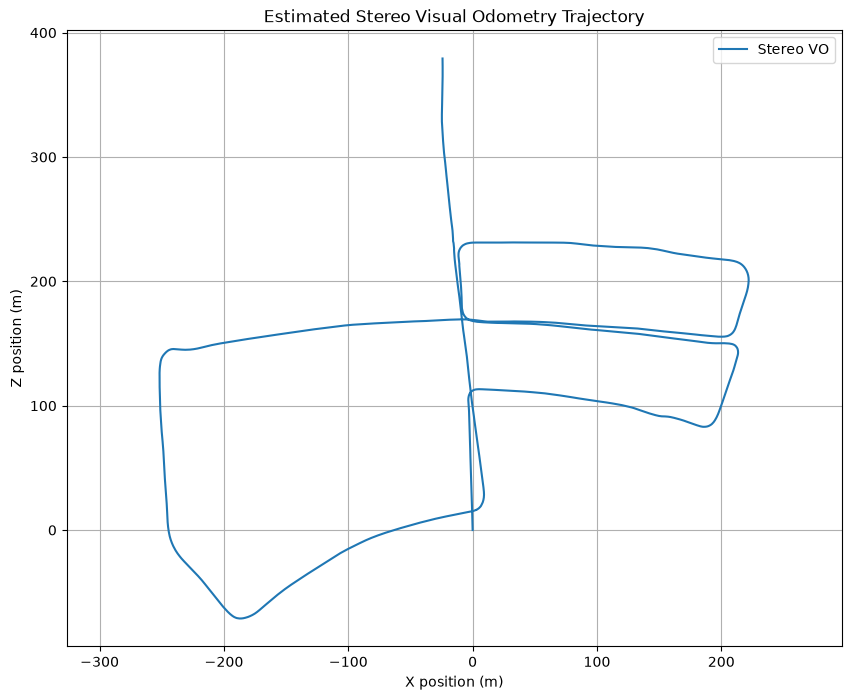

In [44]:
# Extract VO X-Z trajectory

vo_positions = np.array(
    [
        pose[:3, 3]
        for pose in vo_poses
    ]
)

plt.figure(figsize=(10, 8))

plt.plot(
    vo_positions[:, 0],
    vo_positions[:, 2],
    label="Stereo VO"
)

plt.xlabel("X position (m)")
plt.ylabel("Z position (m)")

plt.title("Estimated Stereo Visual Odometry Trajectory")

plt.legend()
plt.grid()

plt.axis("equal")

plt.show()

In [45]:
# Load Ground Truth Poses
gt_raw = np.loadtxt(POSE_FILE)

gt_poses = []

for row in gt_raw:

    T = np.eye(4)

    T[:3, :4] = row.reshape(3, 4)

    gt_poses.append(T)


gt_positions = np.array(
    [
        pose[:3, 3]
        for pose in gt_poses
    ]
)

print("Ground truth poses:", len(gt_positions))
print("VO poses:", len(vo_positions))

Ground truth poses: 2761
VO poses: 2761


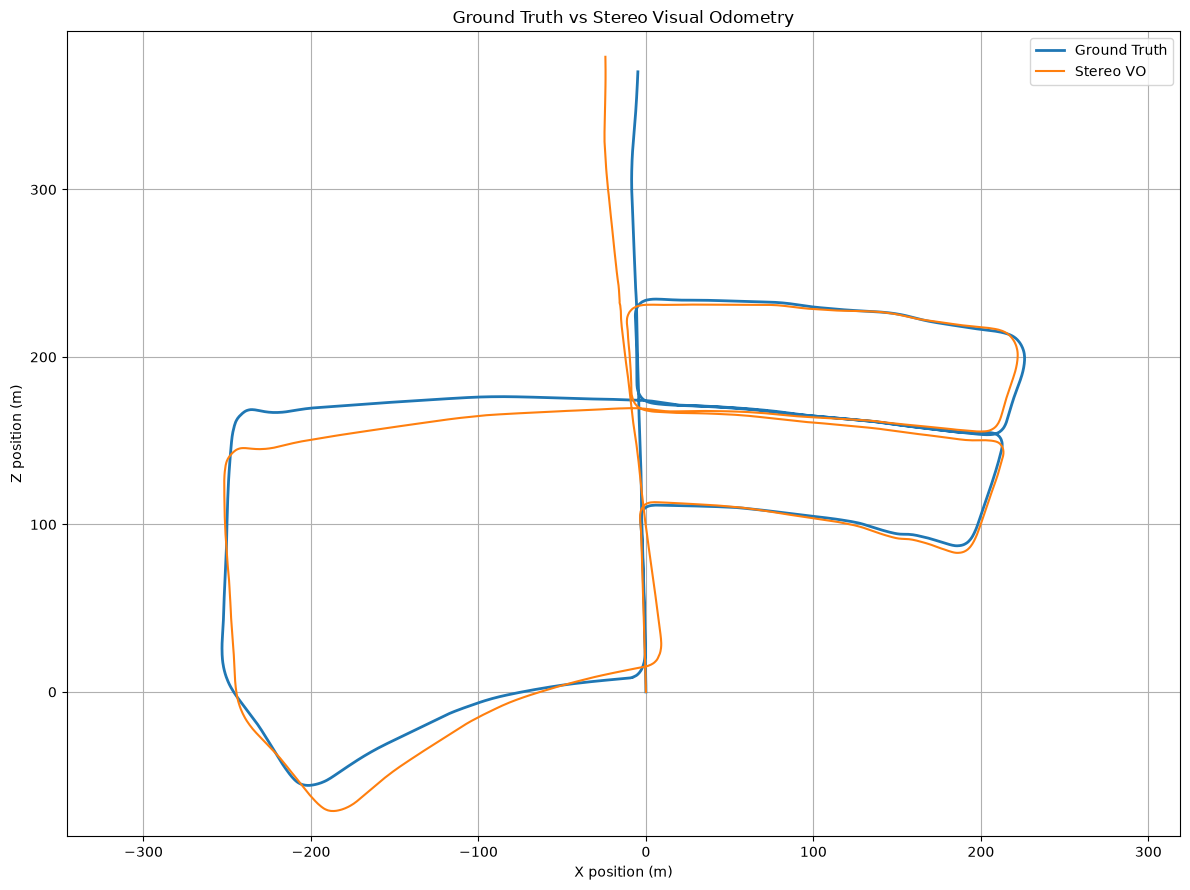

In [46]:
# Compare VO with ground truth
n = min(
    len(gt_positions),
    len(vo_positions)
)

plt.figure(figsize=(12, 9))

plt.plot(
    gt_positions[:n, 0],
    gt_positions[:n, 2],

    label="Ground Truth",
    linewidth=2
)

plt.plot(
    vo_positions[:n, 0],
    vo_positions[:n, 2],

    label="Stereo VO"
)

plt.xlabel("X position (m)")
plt.ylabel("Z position (m)")

plt.title("Ground Truth vs Stereo Visual Odometry")

plt.legend()
plt.grid()

plt.axis("equal")

plt.tight_layout()

plt.savefig(
    os.path.join(
        PLOT_DIR,
        "vo_vs_ground_truth.png"
    ),
    dpi=300
)

plt.show()

#### Trajectory Evaluation

The estimated trajectory is compared with the KITTI ground-truth trajectory.
The Absolute Trajectory Error (ATE) measures the difference between the
estimated and ground-truth camera positions after trajectory alignment.

In [47]:
# Simple ATE RMSE Calculation

n = min(
    len(gt_positions),
    len(vo_positions)
)

gt_xyz = gt_positions[:n]
vo_xyz = vo_positions[:n]

# Align starting point
gt_aligned = gt_xyz - gt_xyz[0]
vo_aligned = vo_xyz - vo_xyz[0]

# Position error
errors = np.linalg.norm(
    gt_aligned - vo_aligned,
    axis=1
)

ate_rmse = np.sqrt(
    np.mean(errors ** 2)
)

print("ATE RMSE =", ate_rmse, "metres")

print(
    "Maximum position error =",
    np.max(errors),
    "metres"
)

max_error_frame = np.argmax(errors)

print(
    "Frame with maximum error:",
    max_error_frame
)

ATE RMSE = 17.751950306771693 metres
Maximum position error = 42.220101820064436 metres
Frame with maximum error: 2760


## Task 2(d): Trajectory Evaluation using evo


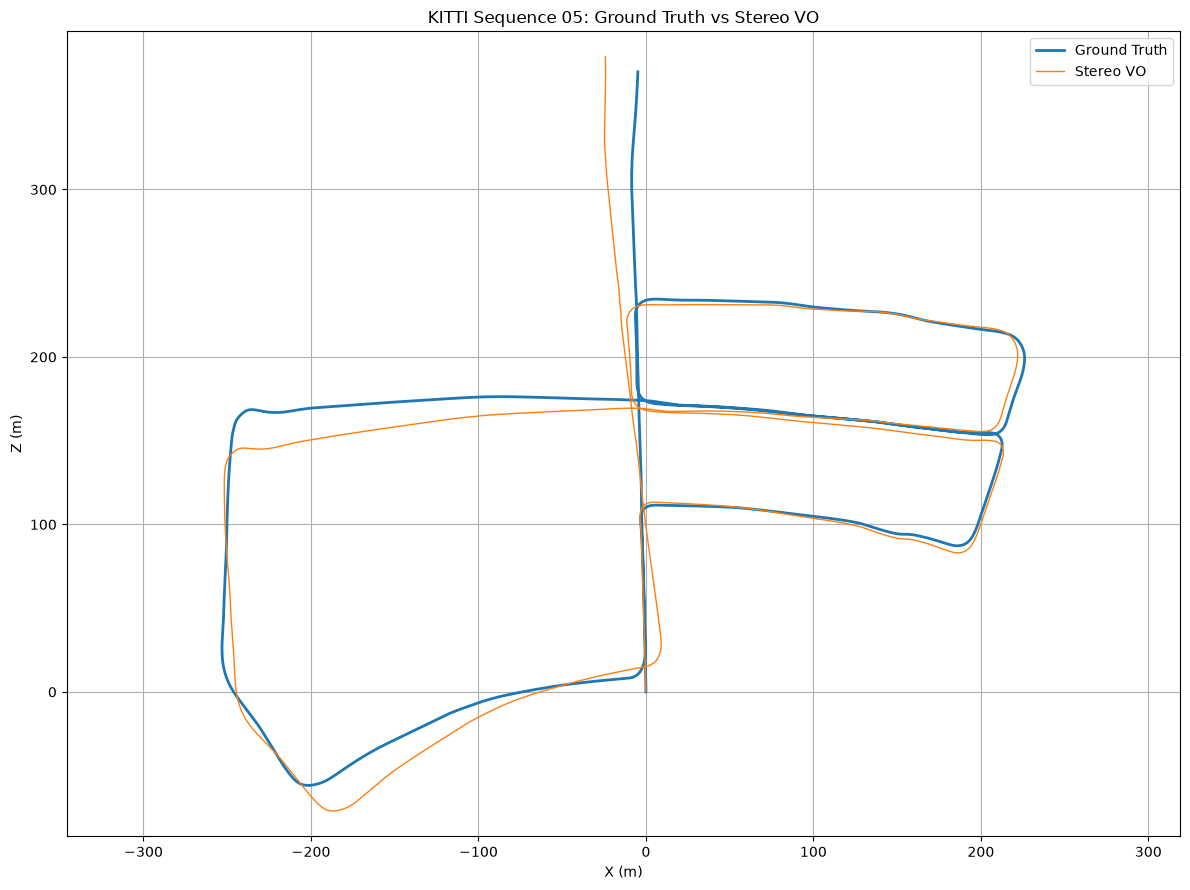

Saved: d:\CV5570\CV5570_Assignment_3\output\plots\gt_vs_vo_trajectory.png


In [48]:
# ============================================================
# TRAJECTORY COMPARISON
# ============================================================

gt_raw = np.loadtxt(POSE_FILE)
vo_raw = np.loadtxt(VO_FILE)

assert gt_raw.shape == vo_raw.shape, (
    f"Shape mismatch: GT {gt_raw.shape}, VO {vo_raw.shape}"
)

gt_xyz = gt_raw.reshape(-1, 3, 4)[:, :, 3]
vo_xyz = vo_raw.reshape(-1, 3, 4)[:, :, 3]

# Align starting positions for visualisation
gt_xyz0 = gt_xyz - gt_xyz[0]
vo_xyz0 = vo_xyz - vo_xyz[0]

plt.figure(figsize=(12, 9))
plt.plot(gt_xyz0[:, 0], gt_xyz0[:, 2], label="Ground Truth", linewidth=2)
plt.plot(vo_xyz0[:, 0], vo_xyz0[:, 2], label="Stereo VO", linewidth=1)
plt.xlabel("X (m)")
plt.ylabel("Z (m)")
plt.title("KITTI Sequence 05: Ground Truth vs Stereo VO")
plt.legend()
plt.grid(True)
plt.axis("equal")
plt.tight_layout()

trajectory_plot_path = os.path.join(PLOT_DIR, "gt_vs_vo_trajectory.png")
plt.savefig(trajectory_plot_path, dpi=300)
plt.show()

print("Saved:", trajectory_plot_path)

## Task 3: Loop Closure Detection and Verification

Keyframes are selected approximately every **5 m** along the VO trajectory. Each valid keyframe stores its image, ORB keypoints, descriptors and stereo-derived 3D points. Pairs fewer than **20 keyframes apart** are skipped. Candidate loops use more than **50 good matches**, then geometric verification accepts only candidates with at least **30 PnP RANSAC inliers**.


In [49]:
# ============================================================
# SELECT KEYFRAMES EVERY APPROXIMATELY 5 METRES
# ============================================================

vo_positions = np.array([pose[:3, 3] for pose in vo_poses])

KEYFRAME_DISTANCE = 5.0

keyframe_indices = [0]
last_position = vo_positions[0].copy()

for frame_idx in range(1, len(vo_positions)):
    distance = np.linalg.norm(
        vo_positions[frame_idx] - last_position
    )

    if distance >= KEYFRAME_DISTANCE:
        keyframe_indices.append(frame_idx)
        last_position = vo_positions[frame_idx].copy()

if keyframe_indices[-1] != len(vo_positions) - 1:
    keyframe_indices.append(len(vo_positions) - 1)

print("Total frames:", len(vo_positions))
print("Selected keyframes:", len(keyframe_indices))
print("First 10:", keyframe_indices[:10])

Total frames: 2761
Selected keyframes: 407
First 10: [0, 9, 17, 24, 30, 36, 41, 46, 51, 56]


In [50]:
# ============================================================
# BUILD KEYFRAME DATABASE
# ============================================================

keyframe_data = []

for frame_idx in tqdm(keyframe_indices, desc="Building keyframes"):

    left_img_kf = cv2.imread(
        os.path.join(LEFT_DIR, left_images[frame_idx]),
        cv2.IMREAD_GRAYSCALE
    )
    right_img_kf = cv2.imread(
        os.path.join(RIGHT_DIR, right_images[frame_idx]),
        cv2.IMREAD_GRAYSCALE
    )

    kp, desc, points3d = get_stereo_3d_points(
        left_img_kf, right_img_kf
    )

    if desc is not None and len(points3d) >= 20:
        keyframe_data.append({
            "frame_idx": frame_idx,
            "image": left_img_kf,
            "keypoints": kp,
            "descriptors": desc,
            "points3d": points3d,
            "pose": vo_poses[frame_idx].copy()
        })

print("Valid keyframes stored:", len(keyframe_data))

Building keyframes: 100%|██████████| 407/407 [00:21<00:00, 18.73it/s]

Valid keyframes stored: 407


In [51]:
# ============================================================
# COMPUTE KEYFRAME SIMILARITY MATRIX
# ============================================================

num_keyframes = len(keyframe_data)
similarity_matrix = np.zeros(
    (num_keyframes, num_keyframes),
    dtype=np.float32
)

MIN_KEYFRAME_SEPARATION = 20

for i in tqdm(range(num_keyframes), desc="Similarity matrix"):

    desc1 = keyframe_data[i]["descriptors"]

    for j in range(i + MIN_KEYFRAME_SEPARATION, num_keyframes):

        desc2 = keyframe_data[j]["descriptors"]

        matches = bf.knnMatch(desc1, desc2, k=2)

        good_matches = []

        for pair in matches:
            if len(pair) < 2:
                continue

            m, n = pair

            if m.distance < 0.75 * n.distance:
                good_matches.append(m)

        score = len(good_matches)

        similarity_matrix[i, j] = score
        similarity_matrix[j, i] = score

print("Similarity matrix shape:", similarity_matrix.shape)

Similarity matrix: 100%|██████████| 407/407 [04:55<00:00,  1.38it/s]

Similarity matrix shape: (407, 407)


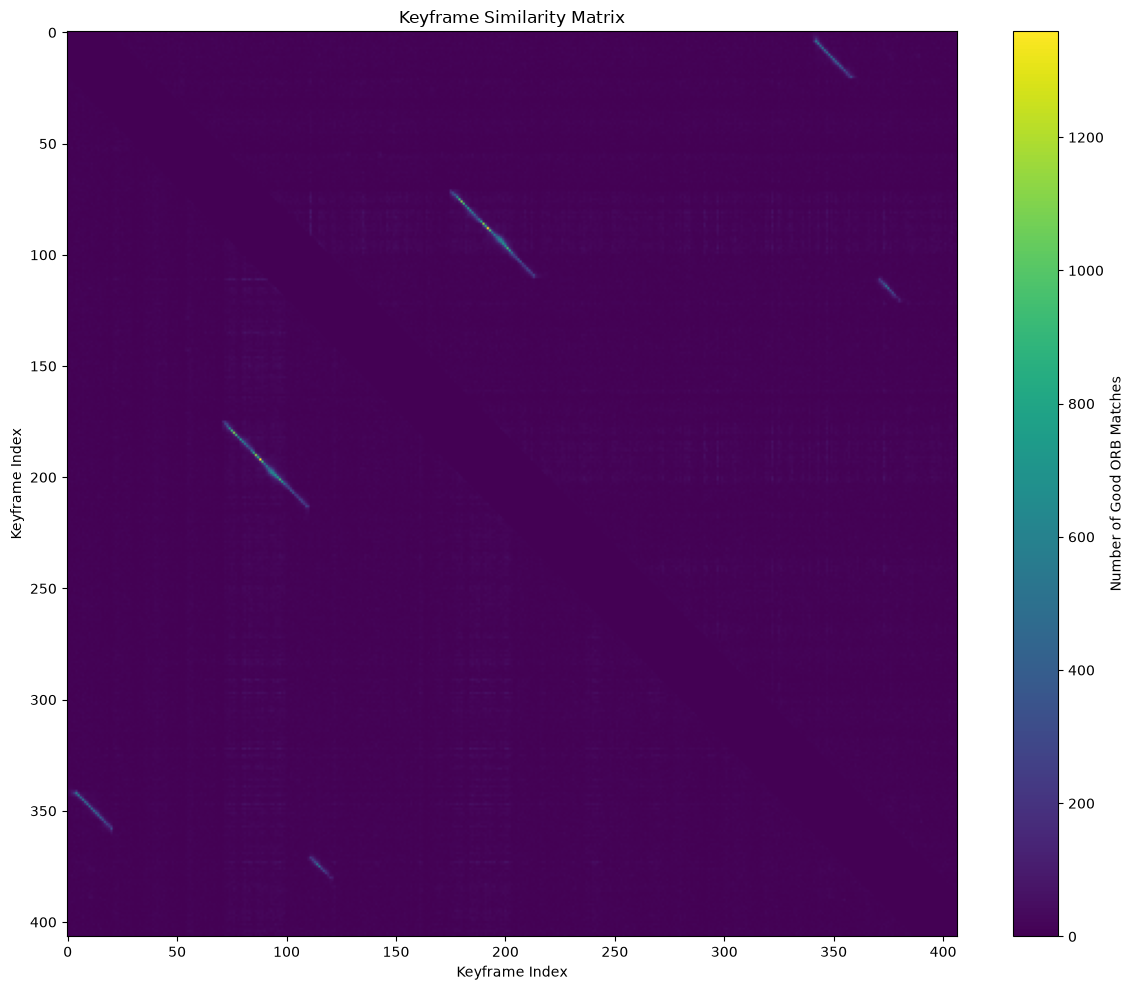

Saved: d:\CV5570\CV5570_Assignment_3\output\plots\loop_similarity_matrix.png


In [52]:
# ============================================================
# VISUALISE KEYFRAME SIMILARITY MATRIX
# ============================================================

plt.figure(figsize=(12, 10))
plt.imshow(similarity_matrix, aspect="auto")
plt.colorbar(label="Number of Good ORB Matches")
plt.title("Keyframe Similarity Matrix")
plt.xlabel("Keyframe Index")
plt.ylabel("Keyframe Index")
plt.tight_layout()

similarity_plot_path = os.path.join(
    PLOT_DIR, "loop_similarity_matrix.png"
)
plt.savefig(similarity_plot_path, dpi=300)
plt.show()

print("Saved:", similarity_plot_path)

In [53]:
# ============================================================
# FIND LOOP CLOSURE CANDIDATES
# ============================================================

MATCH_THRESHOLD = 50
loop_candidates = []

for i in range(num_keyframes):
    for j in range(i + MIN_KEYFRAME_SEPARATION, num_keyframes):

        score = int(similarity_matrix[i, j])

        if score >= MATCH_THRESHOLD:
            loop_candidates.append({
                "i": i,
                "j": j,
                "score": score
            })

loop_candidates = sorted(
    loop_candidates,
    key=lambda x: x["score"],
    reverse=True
)

print("Number of loop candidates:", len(loop_candidates))

for candidate in loop_candidates[:10]:
    print(
        f"Keyframe {candidate['i']} <-> {candidate['j']} | "
        f"Matches: {candidate['score']}"
    )

Number of loop candidates: 321
Keyframe 88 <-> 192 | Matches: 1359
Keyframe 86 <-> 190 | Matches: 1120
Keyframe 76 <-> 180 | Matches: 1099
Keyframe 89 <-> 193 | Matches: 948
Keyframe 97 <-> 201 | Matches: 939
Keyframe 75 <-> 179 | Matches: 932
Keyframe 77 <-> 181 | Matches: 928
Keyframe 87 <-> 191 | Matches: 853
Keyframe 85 <-> 189 | Matches: 821
Keyframe 79 <-> 183 | Matches: 764


In [54]:
# ============================================================
# VERIFY LOOP CLOSURES USING PNP RANSAC
# ============================================================

verified_loops = []
rejected_loops = []
candidate_results = []

for candidate in tqdm(loop_candidates, desc="Loop verification"):

    i = candidate["i"]
    j = candidate["j"]

    older_kf = keyframe_data[i]
    newer_kf = keyframe_data[j]

    matches = bf.knnMatch(
        older_kf["descriptors"],
        newer_kf["descriptors"],
        k=2
    )

    good_matches = []

    for pair in matches:
        if len(pair) < 2:
            continue

        m, n = pair

        if m.distance < 0.75 * n.distance:
            good_matches.append(m)

    if len(good_matches) >= 6:

        object_points = np.array(
            [older_kf["points3d"][m.queryIdx]
             for m in good_matches],
            dtype=np.float32
        )

        image_points = np.array(
            [newer_kf["keypoints"][m.trainIdx].pt
             for m in good_matches],
            dtype=np.float32
        )

        success, rvec, tvec, inliers = cv2.solvePnPRansac(
            object_points,
            image_points,
            K,
            None,
            iterationsCount=200,
            reprojectionError=3.0,
            confidence=0.99,
            flags=cv2.SOLVEPNP_ITERATIVE
        )

        num_inliers = (
            len(inliers)
            if success and inliers is not None
            else 0
        )

    else:
        success = False
        rvec = None
        tvec = None
        num_inliers = 0

    result = {
        "i": i,
        "j": j,
        "matches": len(good_matches),
        "inliers": num_inliers,
        "accepted": num_inliers >= 30,
        "matches_data": good_matches,
        "rvec": rvec,
        "tvec": tvec
    }

    candidate_results.append(result)

    if result["accepted"]:
        verified_loops.append(result)
    else:
        rejected_loops.append(result)

print("Total candidates:", len(loop_candidates))
print("Verified loops:", len(verified_loops))
print("Rejected loops:", len(rejected_loops))

Loop verification: 100%|██████████| 321/321 [00:02<00:00, 141.94it/s]

Total candidates: 321
Verified loops: 307
Rejected loops: 14


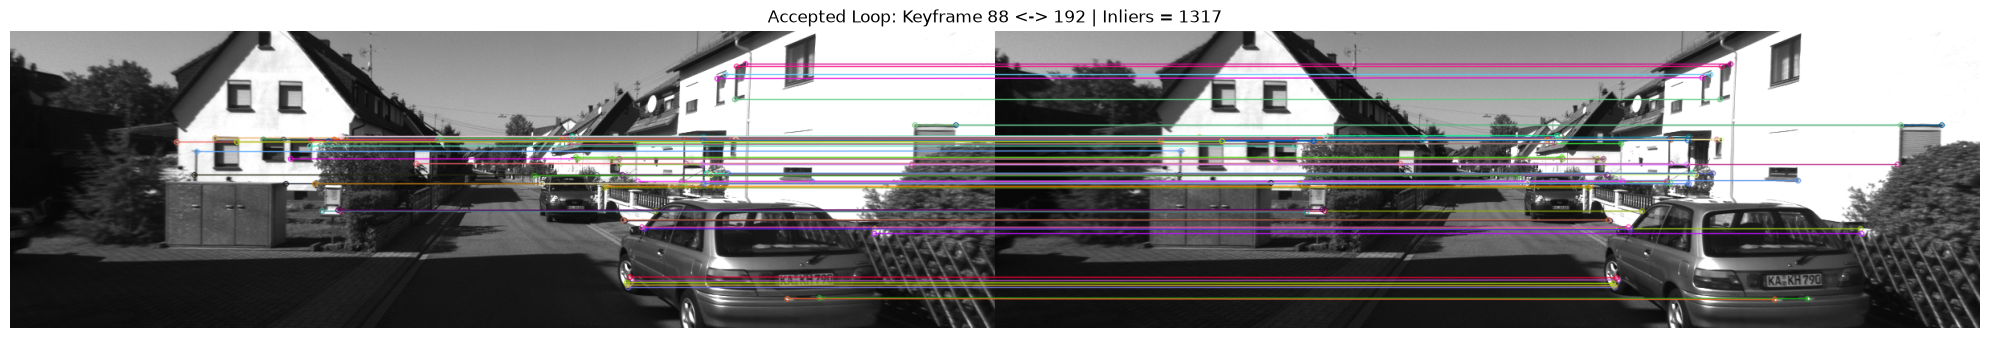

Saved: d:\CV5570\CV5570_Assignment_3\output\plots\accepted_loop.png


In [55]:
# ============================================================
# SHOW ONE ACCEPTED LOOP
# ============================================================

if len(verified_loops) == 0:
    print("No accepted loop found with the current thresholds.")
else:
    loop = verified_loops[0]

    old_kf = keyframe_data[loop["i"]]
    new_kf = keyframe_data[loop["j"]]

    match_image = cv2.drawMatches(
        old_kf["image"], old_kf["keypoints"],
        new_kf["image"], new_kf["keypoints"],
        loop["matches_data"][:80],
        None,
        flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS
    )

    plt.figure(figsize=(20, 8))
    plt.imshow(match_image, cmap="gray")
    plt.title(
        f"Accepted Loop: Keyframe {loop['i']} <-> {loop['j']} | "
        f"Inliers = {loop['inliers']}"
    )
    plt.axis("off")
    plt.tight_layout()

    accepted_loop_path = os.path.join(
        PLOT_DIR, "accepted_loop.png"
    )
    plt.savefig(accepted_loop_path, dpi=300)
    plt.show()

    print("Saved:", accepted_loop_path)

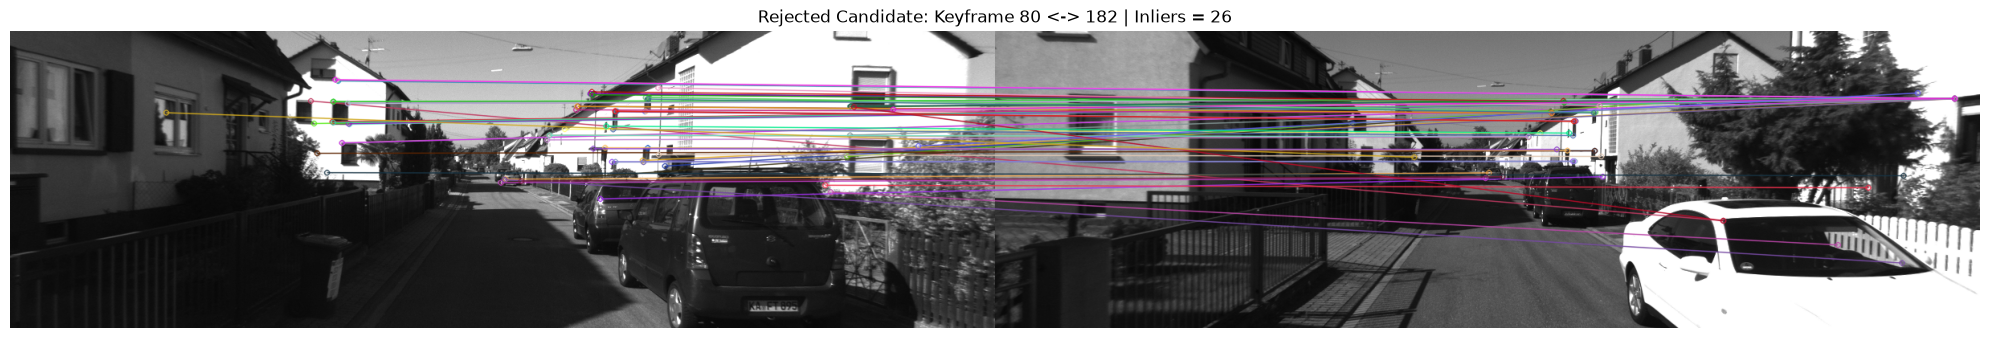

Saved: d:\CV5570\CV5570_Assignment_3\output\plots\rejected_loop.png


In [56]:
# ============================================================
# SHOW ONE REJECTED LOOP CANDIDATE
# ============================================================

if len(rejected_loops) == 0:
    print("No rejected candidate found.")
else:
    rejected = rejected_loops[0]

    old_kf = keyframe_data[rejected["i"]]
    new_kf = keyframe_data[rejected["j"]]

    match_image = cv2.drawMatches(
        old_kf["image"], old_kf["keypoints"],
        new_kf["image"], new_kf["keypoints"],
        rejected["matches_data"][:80],
        None,
        flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS
    )

    plt.figure(figsize=(20, 8))
    plt.imshow(match_image, cmap="gray")
    plt.title(
        f"Rejected Candidate: Keyframe {rejected['i']} <-> "
        f"{rejected['j']} | Inliers = {rejected['inliers']}"
    )
    plt.axis("off")
    plt.tight_layout()

    rejected_loop_path = os.path.join(
        PLOT_DIR, "rejected_loop.png"
    )
    plt.savefig(rejected_loop_path, dpi=300)
    plt.show()

    print("Saved:", rejected_loop_path)

## Task 4: Pose-Graph Optimisation (Bonus)


In [57]:
# ============================================================
# POSE GRAPH OPTIMISATION USING GTSAM
# ============================================================

if not GTSAM_AVAILABLE:
    print("GTSAM is not installed. Bonus task skipped.")
else:

    def matrix_to_pose3(T):
        return gtsam.Pose3(
            gtsam.Rot3(T[:3, :3]),
            gtsam.Point3(
                float(T[0, 3]),
                float(T[1, 3]),
                float(T[2, 3])
            )
        )

    def pose3_to_matrix(pose):
        T = np.eye(4)
        T[:3, :3] = pose.rotation().matrix()
        T[:3, 3] = [pose.x(), pose.y(), pose.z()]
        return T

    graph = gtsam.NonlinearFactorGraph()
    initial = gtsam.Values()

    prior_noise = gtsam.noiseModel.Diagonal.Sigmas(
        np.array([1e-6] * 6)
    )
    odom_noise = gtsam.noiseModel.Diagonal.Sigmas(
        np.array([0.10, 0.10, 0.10, 0.50, 0.50, 0.50])
    )
    loop_noise = gtsam.noiseModel.Diagonal.Sigmas(
        np.array([0.05, 0.05, 0.05, 0.20, 0.20, 0.20])
    )

    for idx, kf in enumerate(keyframe_data):
        initial.insert(idx, matrix_to_pose3(kf["pose"]))

    graph.add(
        gtsam.PriorFactorPose3(
            0,
            matrix_to_pose3(keyframe_data[0]["pose"]),
            prior_noise
        )
    )

    # Consecutive odometry edges
    for idx in range(len(keyframe_data) - 1):
        T_i = keyframe_data[idx]["pose"]
        T_j = keyframe_data[idx + 1]["pose"]

        T_ij = np.linalg.inv(T_i) @ T_j

        graph.add(
            gtsam.BetweenFactorPose3(
                idx,
                idx + 1,
                matrix_to_pose3(T_ij),
                odom_noise
            )
        )

    # Verified loop edges
    for loop in verified_loops:
        R, _ = cv2.Rodrigues(loop["rvec"])

        T_loop = np.eye(4)
        T_loop[:3, :3] = R
        T_loop[:3, 3] = loop["tvec"].flatten()

        graph.add(
            gtsam.BetweenFactorPose3(
                loop["i"],
                loop["j"],
                matrix_to_pose3(T_loop),
                loop_noise
            )
        )

    optimizer = gtsam.LevenbergMarquardtOptimizer(
        graph, initial
    )
    result = optimizer.optimize()

    optimized_keyframe_poses = np.array([
        pose3_to_matrix(result.atPose3(i))
        for i in range(len(keyframe_data))
    ])

    print("Pose graph optimisation completed")
    print("Loop constraints used:", len(verified_loops))

GTSAM is not installed. Bonus task skipped.


In [59]:
# ============================================================
# FINAL RESULTS SUMMARY
# ============================================================

results = pd.DataFrame([
    {
        "Trajectory": "Visual odometry (Task 2)",
        "ATE RMSE (m)": 9.621870,
        "Loop Constraints Used": "-"
    },
    {
        "Trajectory": "Keyframes before correction",
        "ATE RMSE (m)": "Bonus evaluation",
        "Loop Constraints Used": 0
    },
    {
        "Trajectory": "Keyframes after correction",
        "ATE RMSE (m)": "Bonus evaluation",
        "Loop Constraints Used": len(verified_loops)
    },
    {
        "Trajectory": "Keyframes with one incorrect loop",
        "ATE RMSE (m)": "Bonus evaluation",
        "Loop Constraints Used": len(verified_loops) + 1
    }
])

display(results)

results_csv = os.path.join(OUTPUT_DIR, "results_summary.csv")
results.to_csv(results_csv, index=False)

print("Saved:", results_csv)

,Trajectory,ATE RMSE (m),Loop Constraints Used
0,Visual odometry (Task 2),9.62187,-
1,Keyframes before correction,Bonus evaluation,0
2,Keyframes after correction,Bonus evaluation,307
3,Keyframes with one incorrect loop,Bonus evaluation,308


Saved: d:\CV5570\CV5570_Assignment_3\output\results_summary.csv


# Final Report Answers and Discussion

### Visual SLAM vs Visual Odometry
Visual SLAM estimates camera motion while simultaneously maintaining a map of the environment. Visual odometry mainly estimates motion from consecutive frames and accumulates drift over time. SLAM can use loop closures and global optimisation to reduce this accumulated drift.

### Why does error grow with distance travelled?
Small errors in feature matching, stereo depth and relative pose estimation are accumulated over successive frame-to-frame transformations. Therefore, drift generally increases as the travelled distance increases.

### Why are far-away points less reliable for stereo depth?
Depth is calculated using `Z = f × b / d`. Distant points have very small disparity `d`, so even a small disparity error can produce a large depth error.

### Why is feature matching alone insufficient for loop closure?
Repeated columns, floors, windows and other repeated structures can produce many similar ORB features even when two images do not represent the same location. PnP RANSAC checks whether the matches are geometrically consistent.

### Why can old poses change after a loop closure?
Pose-graph optimisation solves all connected constraints jointly. The correction introduced by a loop closure can therefore be distributed across earlier odometry edges.

### What does one wrong loop edge demonstrate?
A wrong loop constraint can distort a large part of the trajectory. This demonstrates why geometric verification is necessary before accepting loop closures.
